# Geospatial Visualization in Python

In this hands-on lecture you will put the principles from [Communicating with Maps and Visualizations](https://hamedalemo.github.io/advanced-geo-python/lectures/26_visualization_principles.html) into code. You will:

1. See why rainbow colormaps mislead, and measure it.
2. Build choropleth maps that normalize, classify and project the data on purpose.
3. Make interactive maps with GeoPandas `.explore()` and Lonboard, and see why data size matters.
4. Look inside map tiles and PMTiles, read one over HTTP range requests, and write your own.
5. Fix a bad map.

All datasets are small files hosted on GitHub ([Natural Earth](https://www.naturalearthdata.com/) via [this repository](https://github.com/nvkelso/natural-earth-vector), the Xarray tutorial data, and the PMTiles test files), so the notebook runs on a laptop.

> Environment
>
> Create the environment from this repository: run `pixi install`, then `pixi run lab`. It includes `geopandas`, `matplotlib`, `xarray`, `mapclassify`, `cmcrameri`, `colorspacious`, `folium`, `lonboard`, `pmtiles`, `mapbox-vector-tile`, `mercantile`, `obstore` and `async-pmtiles`. The Lonboard maps need a running Jupyter session; they do not show up on the course website.

You can access this notebook on this [GitHub repo](https://github.com/HamedAlemo/geo-viz-tutorial).

## Setup

In [1]:
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=SyntaxWarning)  # an old docstring in colorspacious
warnings.filterwarnings("ignore", message="Numba not installed")  # mapclassify works without numba, just slower

import cmcrameri.cm as cmc
import geopandas as gpd
import mapclassify
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pooch
import shapely
import xarray as xr
from colorspacious import cspace_convert
from matplotlib import cbook

pooch.get_logger().setLevel("WARNING")
DATA_DIR = Path("data")
NE = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/"


def fetch(url, fname):
    """Download a file once and return its local path."""
    return pooch.retrieve(url, known_hash=None, fname=fname, path=DATA_DIR, progressbar=False)


countries_path = fetch(NE + "ne_110m_admin_0_countries.geojson", "ne_110m_admin_0_countries.geojson")
places_path = fetch(NE + "ne_10m_populated_places_simple.geojson", "ne_10m_populated_places_simple.geojson")
roads_path = fetch(NE + "ne_10m_roads.geojson", "ne_10m_roads.geojson")
air_path = fetch("https://raw.githubusercontent.com/pydata/xarray-data/master/air_temperature.nc", "air_temperature.nc")

## Color

### The same data, three colormaps

Matplotlib ships with a small digital elevation model (DEM) of the Jacksboro fault in Tennessee. Let's plot it with `jet` (the classic rainbow), `viridis` (the Matplotlib default) and `batlow` (from the Scientific Colour Maps in `cmcrameri`).

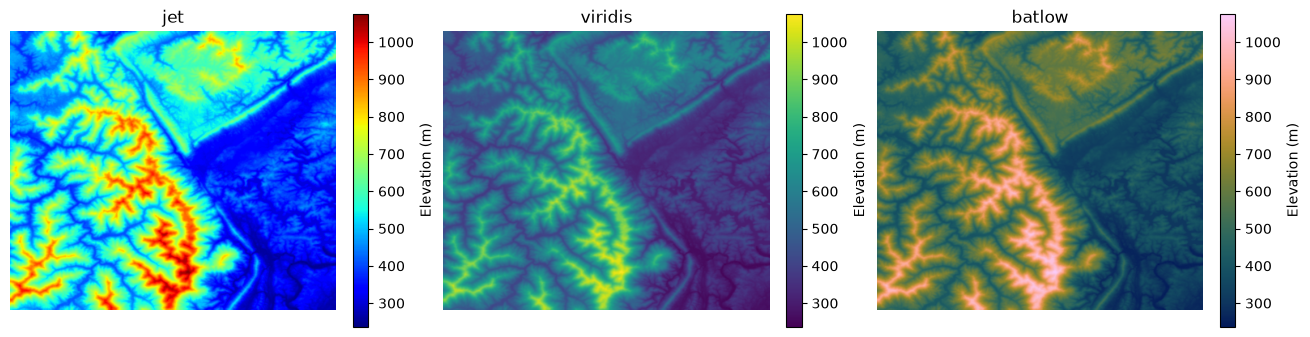

In [2]:
dem = cbook.get_sample_data("jacksboro_fault_dem.npz")["elevation"]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, cmap in zip(axes, ["jet", "viridis", cmc.batlow]):
    im = ax.imshow(dem, cmap=cmap)
    ax.set_title(cmap if isinstance(cmap, str) else cmap.name)
    ax.set_axis_off()
    fig.colorbar(im, ax=ax, shrink=0.8, label="Elevation (m)")

> Question
>
> Without looking at the colorbar, which is higher in the `jet` map: the cyan areas or the red areas? Can you see the sharp edges around the yellow and cyan bands? Is the terrain really that abrupt? Compare with `batlow`.

### Measure it: perceived lightness

Our eyes read "more" and "less" mostly from lightness. We can compute the perceived lightness of every color in a colormap using the CAM02-UCS color space from the `colorspacious` package (the same method Matplotlib's documentation uses). A good sequential colormap should have lightness that changes steadily in one direction.

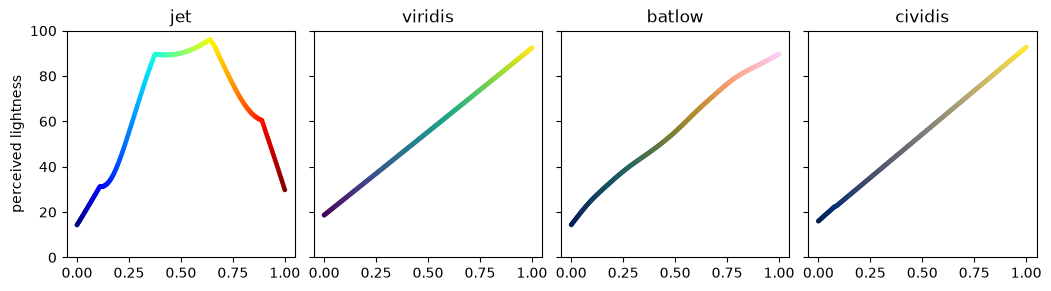

In [3]:
def lightness(rgb):
    """Perceived lightness (J', 0 to 100) of an array of sRGB colors in [0, 1]."""
    return cspace_convert(rgb, "sRGB1", "CAM02-UCS")[..., 0]


def plot_lightness(cmaps):
    x = np.linspace(0, 1, 256)
    fig, axes = plt.subplots(1, len(cmaps), figsize=(2.6 * len(cmaps), 2.8), sharey=True, layout="constrained")
    for ax, cmap in zip(np.atleast_1d(axes), cmaps):
        cmap = plt.get_cmap(cmap)
        ax.scatter(x, lightness(cmap(x)[:, :3]), c=x, cmap=cmap, s=6)
        ax.set_title(cmap.name)
        ax.set_ylim(0, 100)
    np.atleast_1d(axes)[0].set_ylabel("perceived lightness")


plot_lightness(["jet", "viridis", cmc.batlow, "cividis"])

The printed version of a figure shows exactly this lightness. Here is the DEM converted to grayscale after coloring:

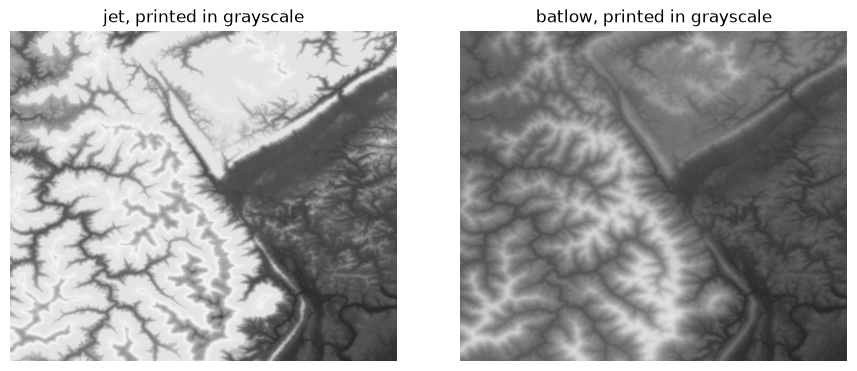

In [4]:
z = (dem - dem.min()) / (dem.max() - dem.min())
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
for ax, cmap in zip(axes, [plt.get_cmap("jet"), cmc.batlow]):
    ax.imshow(lightness(cmap(z)[..., :3]), cmap="gray", vmin=0, vmax=100)
    ax.set_title(f"{cmap.name}, printed in grayscale")
    ax.set_axis_off()

> Exercise 1
>
> Call `plot_lightness` with `["turbo", "terrain", "Spectral", "RdYlGn", "gist_earth"]`. Which of these are safe for ordered data such as elevation? `terrain` is popular for DEMs: is its lightness monotonic?

In [5]:
# Your answer here

### Color vision deficiency

About 8% of men and 0.5% of women have some form of color vision deficiency. `colorspacious` can simulate how a colormap appears to them.

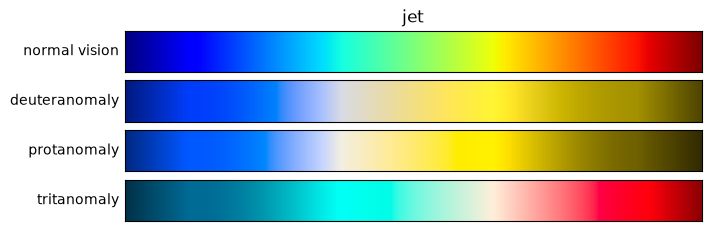

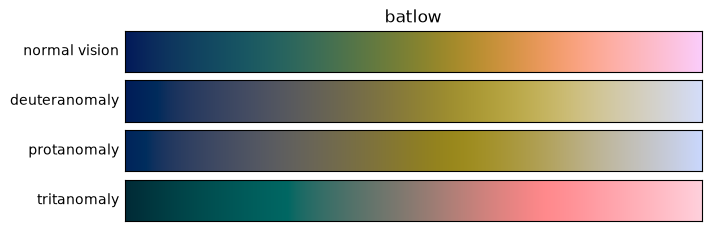

In [6]:
def show_cvd(cmap, severity=100):
    x = np.linspace(0, 1, 256)
    cmap = plt.get_cmap(cmap)
    rows = {"normal vision": cmap(x)[:, :3]}
    for kind in ["deuteranomaly", "protanomaly", "tritanomaly"]:
        sim = cspace_convert(rows["normal vision"], {"name": "sRGB1+CVD", "cvd_type": kind, "severity": severity}, "sRGB1")
        rows[kind] = np.clip(sim, 0, 1)
    fig, axes = plt.subplots(len(rows), 1, figsize=(7, 2.2), layout="constrained")
    for ax, (label, rgb) in zip(axes, rows.items()):
        ax.imshow(rgb[None], aspect="auto")
        ax.set_xticks([]), ax.set_yticks([])
        ax.set_ylabel(label, rotation=0, ha="right", va="center")
    axes[0].set_title(cmap.name)


show_cvd("jet")
show_cvd(cmc.batlow)

### Diverging data: center the colormap

Now consider air temperature anomalies, the difference from the monthly mean. Zero is meaningful here, so we need a diverging colormap centered on zero. We use the NCEP reanalysis sample that ships with the Xarray tutorials.

In [7]:
ds = xr.open_dataset(air_path)
air = ds["air"].astype("float32") - 273.15  # Kelvin to Celsius; float32 uses half the memory of float64
air.attrs["units"] = "°C"
anom = air.groupby("time.month") - air.groupby("time.month").mean()
anom.attrs = {"long_name": "Air temperature anomaly", "units": "°C"}
anom

<xarray.DataArray 'air' (time: 2920, lat: 25, lon: 53)> Size: 15MB
array([[[ -5.149769  ,  -3.8859348 ,  -2.714983  , ..., -10.260975  ,
          -8.587759  ,  -7.0465508 ],
        [ -5.0575104 ,  -4.407297  ,  -4.010296  , ...,  -8.728495  ,
          -8.2084675 ,  -7.4545193 ],
        [ -1.5771465 ,  -1.3964996 ,  -1.824522  , ..., -10.198729  ,
         -10.394405  ,  -9.865572  ],
        ...,
        [  0.7495842 ,   0.9557533 ,   1.172884  , ...,   0.21355629,
           0.44273376,   0.6513214 ],
        [ -0.6447048 ,  -0.27000618,   0.6297474 , ...,   0.5438404 ,
           0.81856537,   0.6698227 ],
        [ -0.8644848 ,  -0.44843483,   0.05083466, ...,   0.8818283 ,
           1.0141792 ,   0.96320915]],

       [[ -4.2497597 ,  -3.685938  ,  -3.114977  , ..., -11.060978  ,
         -10.487753  ,  -9.846554  ],
        [ -5.2575073 ,  -4.807291  ,  -4.510296  , ..., -10.528498  ,
         -11.008471  , -11.054525  ],
        [  1.6228504 ,   1.6934967 ,   1.3854847 , ..., -12.598722  ,
         -13.394405  , -13.065569  ],
...
          -1.4014015 ,  -1.3677101 ],
        [ -1.1782131 ,  -0.19038773,   0.5456581 , ...,  -1.5656548 ,
          -1.7567215 ,  -2.131422  ],
        [ -0.0909462 ,   0.40322304,   0.714447  , ...,  -1.9103451 ,
          -2.0754414 ,  -2.3477268 ]],

       [[ -2.8809013 ,  -3.7309856 ,  -4.622839  , ...,   1.9182854 ,
           0.4663887 ,  -0.8380928 ],
        [  0.15660286,  -0.8702984 ,  -2.0956612 , ...,   0.80049515,
          -0.67453766,  -2.426033  ],
        [ 10.960581  ,  10.658892  ,  10.023823  , ...,   1.8146667 ,
           0.67723274,  -0.77971077],
        ...,
        [ -2.9751835 ,  -2.2867184 ,  -0.7992649 , ...,  -1.1660175 ,
          -1.0014076 ,  -0.9677162 ],
        [ -1.3782253 ,  -0.49037552,   0.14566422, ...,  -1.1656609 ,
          -1.1567154 ,  -1.3314342 ],
        [ -0.1909523 ,   0.10320473,   0.31445312, ...,  -1.1103573 ,
          -1.3754292 ,  -1.8477268 ]]],
      shape=(2920, 25, 53), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 23kB 2013-01-01 ... 2014-12-31T18:00:00
    month    (time) int64 23kB 1 1 1 1 1 1 1 1 1 ... 12 12 12 12 12 12 12 12 12
  * lat      (lat) float32 100B 75.0 72.5 70.0 67.5 65.0 ... 22.5 20.0 17.5 15.0
  * lon      (lon) float32 212B 200.0 202.5 205.0 207.5 ... 325.0 327.5 330.0
Attributes:
    long_name:  Air temperature anomaly
    units:      °C

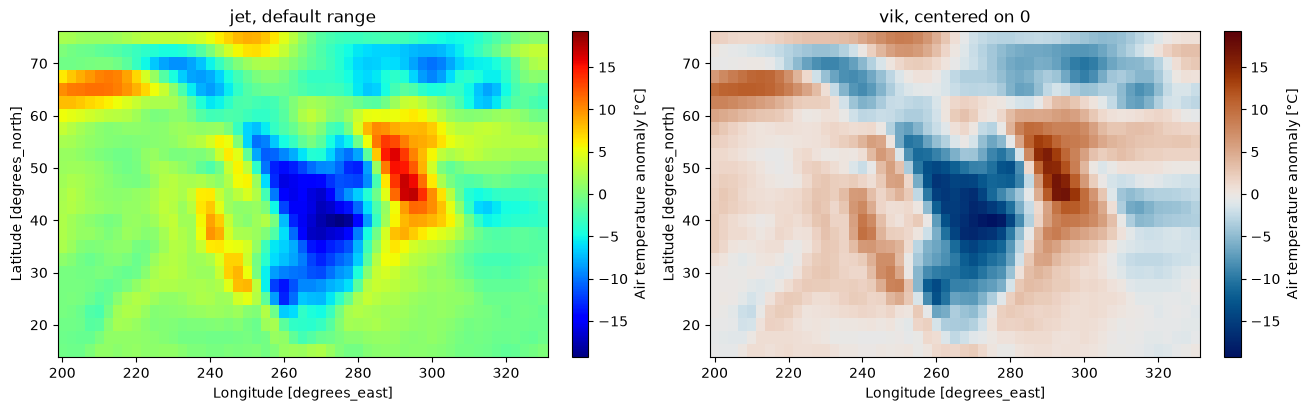

In [8]:
day = anom.sel(time="2014-01-07T00:00")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
day.plot(ax=axes[0], cmap="jet")
axes[0].set_title("jet, default range")
day.plot(ax=axes[1], cmap=cmc.vik, center=0)
axes[1].set_title("vik, centered on 0");

Xarray noticed that the data cross zero and made the color range symmetric in both panels. Even so, in the `jet` panel zero (no anomaly) is a green-cyan that does not stand out, the brightest color (yellow) marks a moderate warm anomaly, and the eye cannot easily separate warm from cold. With `vik` centered on zero, white means "normal", red means warmer and blue colder, and equal distances from zero have equal visual weight.


### Comparing panels: use one scale

When you plot two maps separately, each gets its own color range. A reader comparing them will compare colors that mean different values. Faceting in Xarray (or setting `vmin` and `vmax` yourself) puts all panels on one scale with one colorbar.

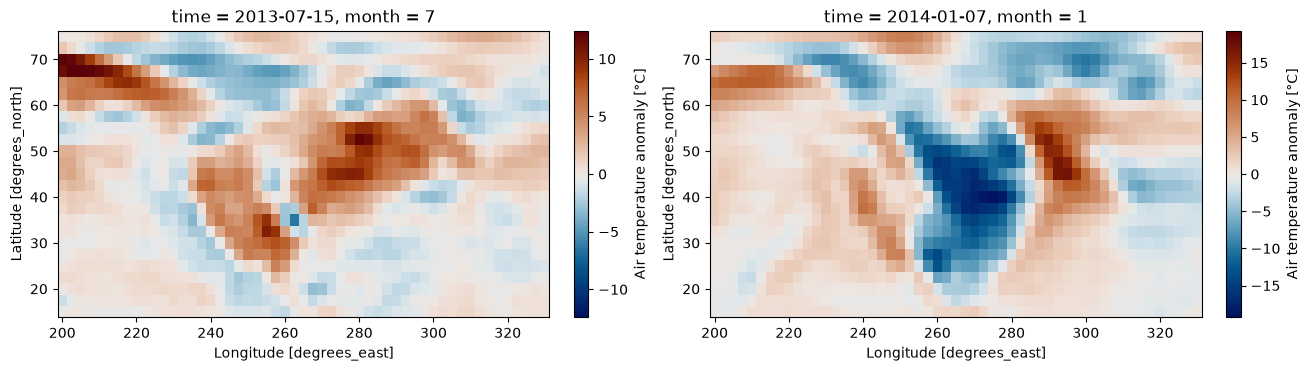

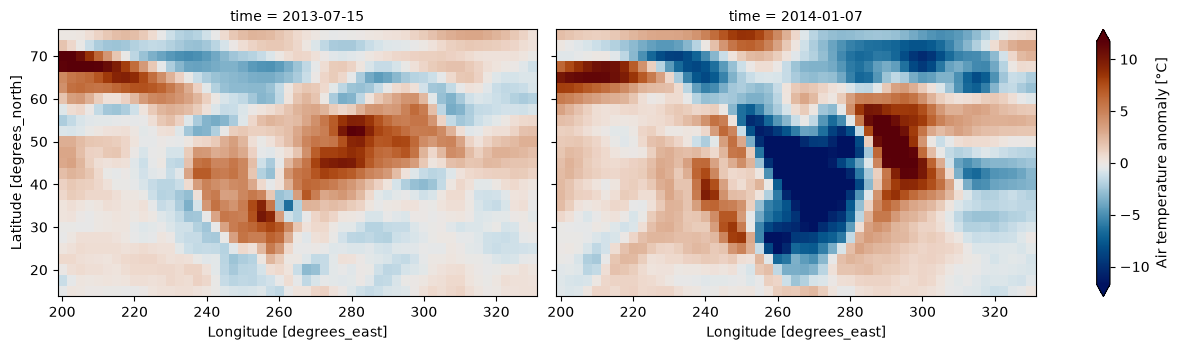

In [9]:
two_days = anom.sel(time=["2013-07-15T00:00", "2014-01-07T00:00"])

# Wrong: each panel gets its own range
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), layout="constrained")
for ax, t in zip(axes, two_days.time):
    two_days.sel(time=t).plot(ax=ax, cmap=cmc.vik)

# Right: one shared, symmetric scale
two_days.plot(col="time", cmap=cmc.vik, center=0, robust=True, figsize=(13, 3.6));

`robust=True` sets the color limits to the 2nd and 98th percentiles, so a few extreme pixels do not wash out the rest. The triangular ends of the colorbar tell the reader that some values are beyond the limits.


### The same rules apply to charts

Not every figure needs to be a map. Here is the regional mean anomaly as a time series, first the default way, then made explanatory: a title that states the message, units, a zero line, and less clutter.

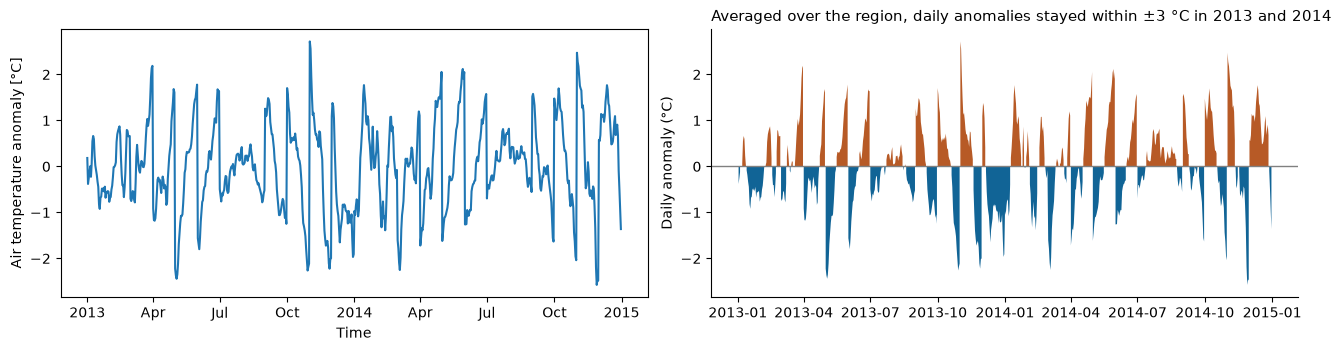

In [10]:
weights = np.cos(np.deg2rad(anom.lat))  # grid cells get smaller toward the pole
regional = anom.weighted(weights).mean(["lat", "lon"]).resample(time="1D").mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), layout="constrained")
regional.plot(ax=axes[0])  # default

ax = axes[1]
ax.axhline(0, color="0.5", lw=1)
ax.fill_between(regional.time.values, regional.values, 0, where=regional.values > 0, color=cmc.vik(0.8), lw=0)
ax.fill_between(regional.time.values, regional.values, 0, where=regional.values < 0, color=cmc.vik(0.2), lw=0)
ax.set_ylabel("Daily anomaly (°C)")
ax.set_title("Averaged over the region, daily anomalies stayed within ±3 °C in 2013 and 2014", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)

## Choropleth Maps

### Counts or rates?

We use Natural Earth country boundaries with their population estimates. Antarctica is dropped. To compute areas and densities we first project to Equal Earth (EPSG:8857), an equal-area projection.

In [11]:
world = gpd.read_file(countries_path)
world = world.loc[world["NAME"] != "Antarctica", ["NAME", "ISO_A3", "CONTINENT", "POP_EST", "GDP_MD", "geometry"]]
world_ea = world.to_crs("EPSG:8857")
world_ea["area_km2"] = world_ea.area / 1e6
world_ea["density"] = world_ea["POP_EST"] / world_ea["area_km2"]
world_ea.sort_values("density", ascending=False).head()

,NAME,ISO_A3,CONTINENT,POP_EST,GDP_MD,geometry,area_km2,density
99,Bangladesh,BGD,Asia,163046161.0,302571,"POLYGON ((8568892.999 2796633.753, 8586671.447...",133712.482996,1219.378755
79,Palestine,PSE,Asia,4685306.0,16276,"POLYGON ((3151667.493 3941252.352, 3111811.269...",5036.412858,930.286323
140,Taiwan,TWN,Asia,23568378.0,1127000,"POLYGON ((11169405.174 3086232.747, 11176611.6...",34311.270861,686.899010
77,Lebanon,LBN,Asia,6855713.0,51991,"POLYGON ((3161493.926 4151743.847, 3138022.753...",10096.043450,679.049475
169,Rwanda,RWA,Africa,12626950.0,10354,"POLYGON ((2913872.815 -145784.721, 2951564.335...",23364.503066,540.433065


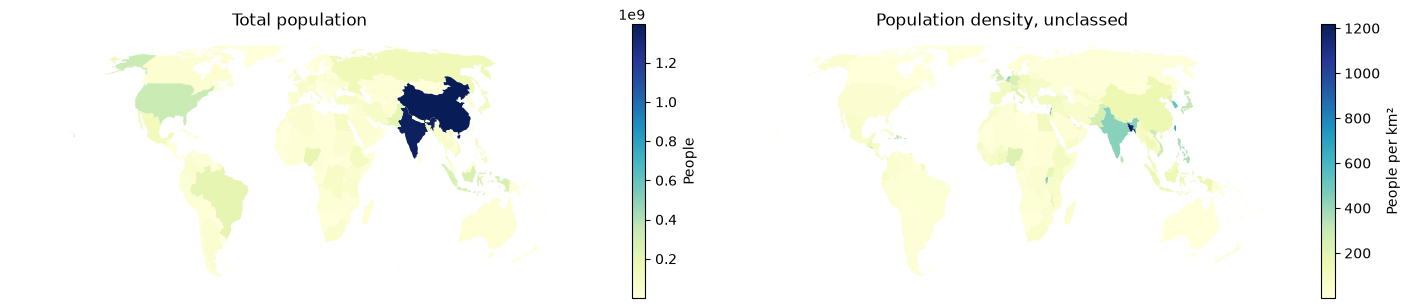

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout="constrained")
world_ea.plot(ax=axes[0], column="POP_EST", cmap="YlGnBu", legend=True, legend_kwds={"label": "People", "shrink": 0.7})
axes[0].set_title("Total population")
world_ea.plot(ax=axes[1], column="density", cmap="YlGnBu", legend=True, legend_kwds={"label": "People per km²", "shrink": 0.7})
axes[1].set_title("Population density, unclassed")
for ax in axes:
    ax.set_axis_off()

The left map says "China and India", and almost nothing else. The density map is better, but it has a different problem: a handful of very dense countries (Bangladesh, small island and city states) stretch the color ramp, so almost every other country looks the same pale color. Look at the distribution:

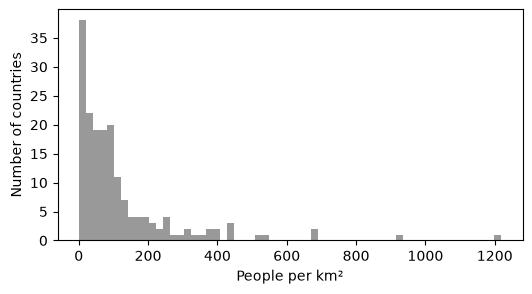

In [13]:
ax = world_ea["density"].plot.hist(bins=60, color="0.6", figsize=(6, 3))
ax.set_xlabel("People per km²")
ax.set_ylabel("Number of countries");

### Classification

With skewed data like this, a classed map usually works better. GeoPandas passes the `scheme` argument to `mapclassify`. Let's compare three schemes with five classes each.

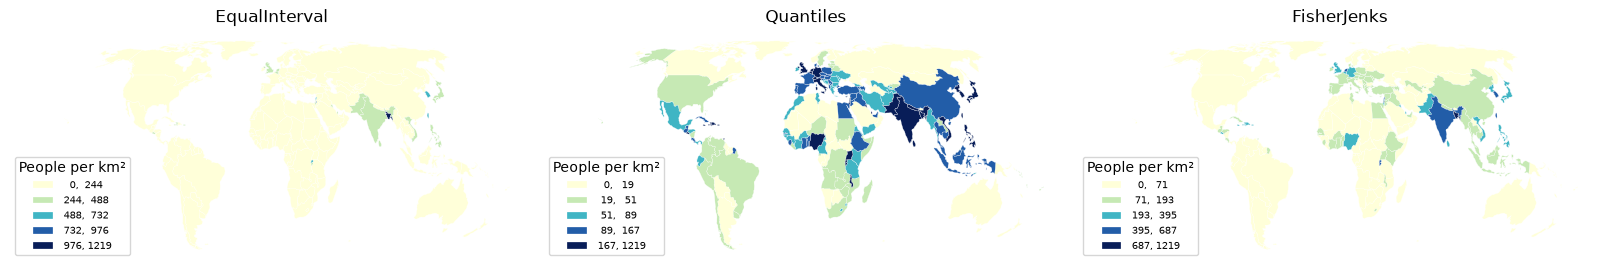

In [14]:
schemes = ["EqualInterval", "Quantiles", "FisherJenks"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")
for ax, scheme in zip(axes, schemes):
    world_ea.plot(ax=ax, column="density", scheme=scheme, k=5, cmap="YlGnBu", edgecolor="white", linewidth=0.2,
                  legend=True, legend_kwds={"title": "People per km²", "fmt": "{:.0f}", "loc": "lower left", "fontsize": 7})
    ax.set_title(scheme)
    ax.set_axis_off()

In [15]:
for scheme in schemes:
    c = getattr(mapclassify, scheme)(world_ea["density"], k=5)
    print(f"{scheme:>14}: upper bounds {np.round(c.bins).astype(int)}, countries per class {c.counts}")

 EqualInterval: upper bounds [ 244  488  732  976 1219], countries per class [153  17   4   1   1]
     Quantiles: upper bounds [  19   51   89  167 1219], countries per class [36 35 35 35 35]
   FisherJenks: upper bounds [  71  193  395  687 1219], countries per class [89 59 19  7  2]


> Question
>
> Which scheme puts 153 of 176 countries in the lowest class? Which one would you use to show "where people are densely concentrated", and which to rank countries into fifths? There is no single right answer, but you should be able to defend your choice and name it in the legend.



### Projection

Web Mercator (EPSG:3857) is the projection of almost every web map. Let's compare areas measured in Web Mercator with true areas from Equal Earth.

In [16]:
world_wm = world.to_crs("EPSG:3857")
cmp = world_ea.set_index("NAME")[["area_km2"]].assign(area_webmercator_km2=world_wm.set_index("NAME").area / 1e6)
cmp["inflation"] = cmp["area_webmercator_km2"] / cmp["area_km2"]
cmp.loc[["Greenland", "Canada", "United States of America", "Brazil", "Dem. Rep. Congo", "Indonesia"]].round(1)

,area_km2,area_webmercator_km2,inflation
NAME,,,
Greenland,2206878.9,36285503.0,16.4
Canada,10033994.2,52166480.7,5.2
United States of America,9513248.9,21862279.6,2.3
Brazil,8508179.1,9059541.4,1.1
Dem. Rep. Congo,2323379.2,2358239.7,1.0
Indonesia,1817750.9,1840122.0,1.0


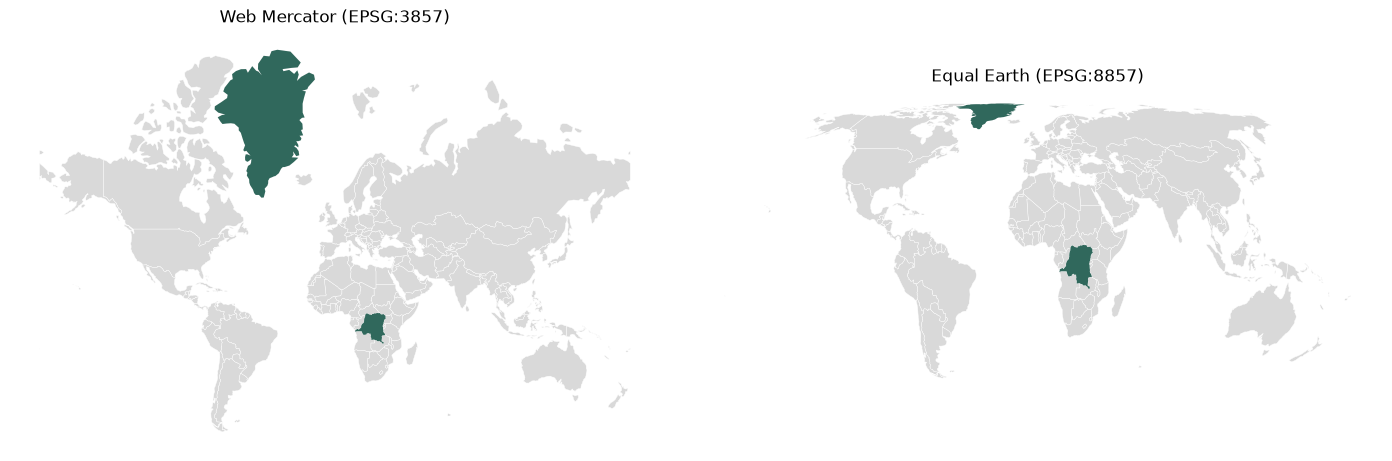

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")
for ax, gdf, title in [(axes[0], world_wm, "Web Mercator (EPSG:3857)"), (axes[1], world_ea, "Equal Earth (EPSG:8857)")]:
    gdf.plot(ax=ax, color="0.85", edgecolor="white", linewidth=0.3)
    gdf[gdf["NAME"].isin(["Greenland", "Dem. Rep. Congo"])].plot(ax=ax, color=cmc.batlow(0.3))
    ax.set_title(title)
    ax.set_axis_off()

In Web Mercator, Greenland looks much larger than the Democratic Republic of the Congo. In reality the Congo is slightly larger. For choropleths, density maps, and any area calculation, use an equal-area CRS.


### A finished map

Putting it together: a rate, a stated classification, an equal-area projection, a title with the message, a legend with units, and the source.

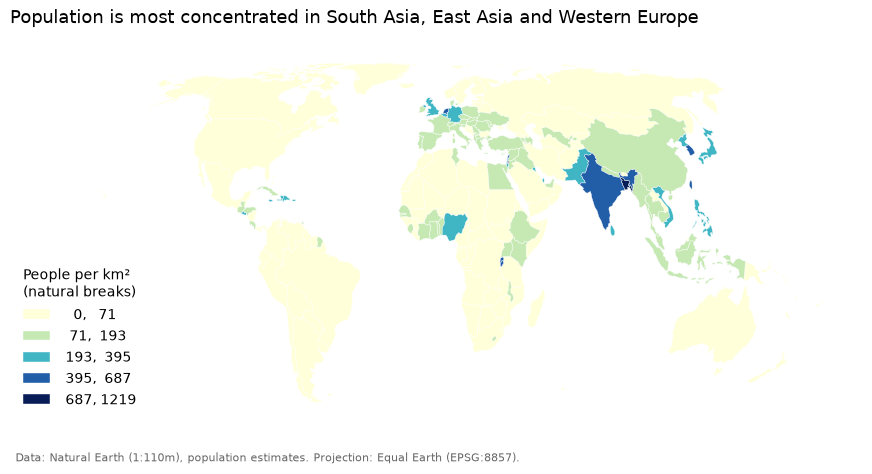

In [36]:
fig, ax = plt.subplots(figsize=(11, 5.5))
world_ea.plot(ax=ax, column="density", scheme="FisherJenks", k=5, cmap="YlGnBu",
              edgecolor="white", linewidth=0.3, legend=True,
              legend_kwds={"title": "People per km²\n(natural breaks)", "fmt": "{:.0f}", "loc": "lower left", "frameon": False})
ax.set_title("Population is most concentrated in South Asia, East Asia and Western Europe", loc="left", fontsize=13)
ax.set_axis_off()
fig.text(0.13, 0.08, "Data: Natural Earth (1:110m), population estimates. Projection: Equal Earth (EPSG:8857).", fontsize=8, color="0.4");

## Interactive Maps

### Small data: `.explore()`

For small datasets, `GeoDataFrame.explore()` creates an interactive Leaflet map with `folium`. It accepts the same `column`, `scheme` and `cmap` arguments as `.plot()`. Hover over a country to see its attributes. Note that `.explore()` reprojects to Web Mercator for display, because that is what the basemap tiles use.

In [19]:
world_ea.explore(column="density", scheme="FisherJenks", k=5, cmap="YlGnBu",
                 tooltip=["NAME", "POP_EST", "density"], legend_kwds={"caption": "People per km²"})

### When data gets bigger

Folium converts the whole GeoDataFrame to GeoJSON text and sends it to the browser. That is fine for 176 countries. Let's look at a larger dataset: the Natural Earth roads (1:10m).

In [20]:
# read only the columns we need
roads = gpd.read_file(roads_path, columns=["type", "name"])
places = gpd.read_file(places_path, columns=["name", "adm0name", "pop_max"])

n_coords = shapely.get_num_coordinates(roads.geometry).sum()
print(f"{len(roads):,} road features with {n_coords:,} vertices")

roads.to_parquet(DATA_DIR / "roads.parquet")
print(f"GeoJSON:    {Path(roads_path).stat().st_size / 1e6:6.1f} MB")
print(f"GeoParquet: {(DATA_DIR / 'roads.parquet').stat().st_size / 1e6:6.1f} MB")

56,600 road features with 709,166 vertices
GeoJSON:      50.5 MB
GeoParquet:    8.4 MB


About 57,000 lines and 700,000 vertices: 50 MB as GeoJSON text, but a fraction of that as GeoParquet. Calling `roads.explore()` would push all 50 MB of text into your browser and can freeze it (try it at your own risk). This is where Lonboard helps.


### Lonboard

The quickest way in is `viz()`, which chooses layer types for you. Let's try it on the 7,300 populated places. Every Lonboard map keeps its own copy of its data, in Python and in your browser, so we will draw the roads only once, in the styled map below.

In [21]:
from lonboard import Map, PathLayer, ScatterplotLayer, viz
from lonboard.basemap import CartoStyle, MaplibreBasemap
from lonboard.colormap import apply_categorical_cmap, apply_continuous_cmap

viz(places)

For more control, build the layers yourself. Each styling property can be a single value or one value per feature, given as a NumPy array. Here we color roads by type with a qualitative (Okabe-Ito) palette, and draw cities as circles whose area is proportional to population (proportional symbols, since population is a count) and whose color shows the same value on a log scale with `batlow`.

In [22]:
road_colors = {
    "Major Highway": [213, 94, 0],
    "Secondary Highway": [0, 114, 178],
    "Road": [150, 150, 150],
}
road_type = roads["type"].where(roads["type"].isin(road_colors.keys()), "Road")

roads_layer = PathLayer.from_geopandas(
    roads,
    get_color=apply_categorical_cmap(road_type, road_colors),
    get_width=np.where(road_type == "Major Highway", 1.5, 0.7),
    width_units="pixels",
)

pop = places["pop_max"].clip(lower=1_000).to_numpy()
norm = mcolors.LogNorm(vmin=1e4, vmax=pop.max(), clip=True)
cities_layer = ScatterplotLayer.from_geopandas(
    places,
    get_fill_color=apply_continuous_cmap(norm(pop), cmc.batlow, alpha=0.85),
    get_radius=np.sqrt(pop) * 15,  # area proportional to population
    radius_units="meters",
    radius_min_pixels=1.5,
    stroked=False,
)

m = Map([roads_layer, cities_layer], basemap=MaplibreBasemap(style=CartoStyle.Positron), height=550)
m

Click a road or a city to see its attributes. Zoom in on Worcester and notice how smoothly it pans with 57,000 lines on screen.

> Performance tip
>
> Changing a property of an existing layer only sends that property to the browser. Re-creating the map sends all the data again. Run the next cell and watch the map above change.

In [23]:
cities_layer.get_fill_color = apply_continuous_cmap(norm(pop), cmc.lajolla, alpha=0.85)
roads_layer.opacity = 0.5

Finally, save the map as a standalone HTML file you can share or embed in a website:

In [24]:
m.to_html("roads_and_cities.html", title="Roads and populated places (Natural Earth)")

> Memory
>
> Each Lonboard map keeps a copy of its data in the Python kernel and in your browser tab, and it stays there as long as the map's output is on the page. With large data, make one map and change its layers instead of making many maps, and close maps you no longer need with `m.close()` (or clear the cell output). Also keep JupyterLab's Settings > Save Widget State Automatically turned off: otherwise all of that data is written into the .ipynb file when you save.

## Tiles and PMTiles

### The tile pyramid

The `mercantile` package does the tile arithmetic for the Web Mercator grid. Which tile contains Clark University at each zoom level, and how many tiles are there in the world?

In [25]:
import mercantile

clark = (-71.8227, 42.2510)  # lon, lat
for z in [0, 4, 8, 12, 16, 18]:
    t = mercantile.tile(*clark, z)
    print(f"z={z:>2}  tile {t.z}/{t.x}/{t.y}   tiles in the world: {4**z:>15,}")

z= 0  tile 0/0/0   tiles in the world:               1
z= 4  tile 4/4/5   tiles in the world:             256
z= 8  tile 8/76/94   tiles in the world:          65,536
z=12  tile 12/1230/1516   tiles in the world:      16,777,216
z=16  tile 16/19693/24266   tiles in the world:   4,294,967,296
z=18  tile 18/78772/97065   tiles in the world:  68,719,476,736


How many tiles would you need to cover Massachusetts at different zoom levels? This is roughly what a tile generator has to create.

In [26]:
ma_bbox = (-73.51, 41.24, -69.93, 42.89)
for z in [6, 10, 14, 16]:
    n = sum(1 for _ in mercantile.tiles(*ma_bbox, zooms=z))
    print(f"z={z:>2}: {n:>9,} tiles")

z= 6:         2 tiles
z=10:        96 tiles
z=14:    16,728 tiles
z=16:   265,118 tiles


### Reading a PMTiles file with HTTP range requests

The PMTiles project keeps a small vector tile archive of Florence, Italy, built from OpenStreetMap, in its GitHub repository. GitHub serves files with support for HTTP range requests, so we can treat it like a cloud bucket.

We give the `pmtiles` reader a function that fetches a byte range, and we count every byte we download.

In [27]:
import requests
from pmtiles.reader import Reader

URL = "https://raw.githubusercontent.com/protomaps/PMTiles/main/spec/v3/protomaps(vector)ODbL_firenze.pmtiles"
file_size = int(requests.head(URL, allow_redirects=True).headers["Content-Length"])

downloaded = []


def get_bytes(offset, length):
    """Fetch `length` bytes starting at `offset` with an HTTP range request."""
    r = requests.get(URL, headers={"Range": f"bytes={offset}-{offset + length - 1}"})
    r.raise_for_status()
    downloaded.append(length)
    return r.content


reader = Reader(get_bytes)
header = reader.header()
print(f"File size: {file_size / 1e6:.1f} MB")
print(f"Tile type: {header['tile_type'].name}, zoom {header['min_zoom']} to {header['max_zoom']}, "
      f"{header['addressed_tiles_count']} tiles")
print(f"Root directory starts at byte {header['root_offset']} (the header is 127 bytes)")
print(f"Layers: {[layer['id'] for layer in reader.metadata()['vector_layers']]}")

File size: 6.6 MB
Tile type: MVT, zoom 0 to 15, 92 tiles
Root directory starts at byte 127 (the header is 127 bytes)
Layers: ['boundaries', 'buildings', 'earth', 'landcover', 'landuse', 'natural', 'physical_line', 'physical_point', 'places', 'pois', 'roads', 'transit', 'water']


Now fetch the single zoom-14 tile that contains the Duomo of Florence:

In [28]:
z = 14
duomo = mercantile.tile(11.2560, 43.7731, z)
tile_bytes = reader.get(duomo.z, duomo.x, duomo.y)

print(f"Tile {duomo.z}/{duomo.x}/{duomo.y}: {len(tile_bytes) / 1e3:.0f} KB (compressed)")
print(f"{len(downloaded)} range requests, {sum(downloaded) / 1e3:.0f} KB downloaded "
      f"= {100 * sum(downloaded) / file_size:.1f}% of the file")

Tile 14/8704/5971: 84 KB (compressed)
6 range requests, 107 KB downloaded = 1.6% of the file


The reader fetched the header, the directory and one tile, and nothing else. A map in your browser does exactly the same thing, for the 10 to 20 tiles that cover the screen.


### What is inside a vector tile?

A vector tile is a small binary (Protocol Buffers) file in the Mapbox Vector Tile format, here also gzip compressed. Let's decode it.

In [37]:
import gzip

import mapbox_vector_tile

tile = mapbox_vector_tile.decode(gzip.decompress(tile_bytes))
for layer_name, layer in tile.items():
    print(f"{layer_name:>15}: {len(layer['features']):4d} features, extent {layer['extent']}")

      buildings:   16 features, extent 4096
          earth:    1 features, extent 4096
        landuse:  201 features, extent 4096
        natural:    1 features, extent 4096
  physical_line:    1 features, extent 4096
 physical_point:    2 features, extent 4096
         places:    4 features, extent 4096
           pois:  226 features, extent 4096
          roads:  590 features, extent 4096
        transit:   83 features, extent 4096
          water:    5 features, extent 4096


Each layer has an extent of 4096: geometry coordinates are integers on a 4096 by 4096 grid inside the tile, not longitudes and latitudes. Let's draw the roads and buildings layers of this one tile in tile coordinates.

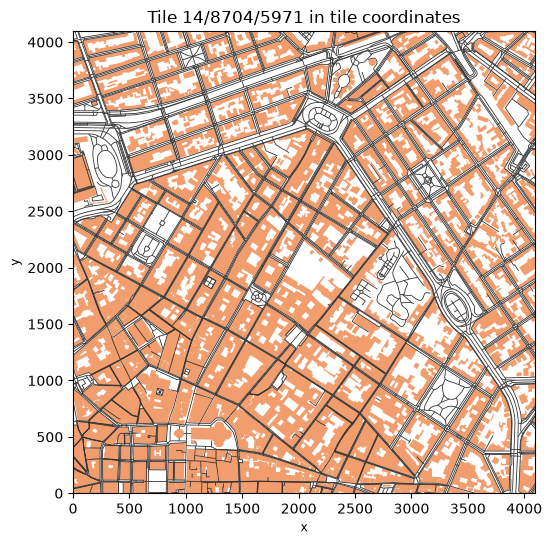

In [30]:
from shapely.geometry import shape

fig, ax = plt.subplots(figsize=(6, 6))
for layer_name, color, kw in [("buildings", cmc.batlow(0.75), {"edgecolor": "none"}), ("roads", "0.2", {"linewidth": 0.6})]:
    geoms = [shape(f["geometry"]) for f in tile[layer_name]["features"]]
    gpd.GeoSeries(geoms).plot(ax=ax, color=color, **kw)
ax.set_xlim(0, 4096)
ax.set_ylim(0, 4096)
ax.set_title(f"Tile {duomo.z}/{duomo.x}/{duomo.y} in tile coordinates");

Notice that roads stop at the tile edge: features are clipped to the tile (plus a small buffer). The same road continues in the neighboring tile as a separate piece. At lower zoom levels, geometries are also simplified and small features dropped. That is why tiles are a format for display and not for analysis: you cannot compute a road's length or a building's area reliably from tiles.


### Make your own PMTiles

GDAL (3.8 and later) can write PMTiles, so GeoPandas can too. We write the roads for zoom levels 0 to 7. This takes about half a minute.

In [31]:
pmtiles_path = DATA_DIR / "roads.pmtiles"
pmtiles_path.unlink(missing_ok=True)  # the PMTiles driver cannot overwrite an existing file
roads.to_file(pmtiles_path, driver="PMTiles", layer="roads", MINZOOM=0, MAXZOOM=7)
print(f"roads.pmtiles: {pmtiles_path.stat().st_size / 1e6:.1f} MB")

roads.pmtiles: 10.7 MB


Open the local file with the reader, this time from disk, and count the features in the tile containing Worcester at different zoom levels.

In [32]:
from pmtiles.reader import MmapSource

with open(pmtiles_path, "rb") as f:
    local = Reader(MmapSource(f))
    for z in [2, 4, 7]:
        t = mercantile.tile(-71.80, 42.26, z)
        data = local.get(t.z, t.x, t.y)
        layer = mapbox_vector_tile.decode(gzip.decompress(data))["roads"]
        print(f"z={z}: tile {t.z}/{t.x}/{t.y} is {len(data) / 1e3:6.0f} KB with {len(layer['features']):5,} features")

z=2: tile 2/1/1 is    150 KB with 8,281 features
z=4: tile 4/4/5 is     40 KB with 1,786 features
z=7: tile 7/38/47 is      5 KB with   219 features


The zoom 2 tile covers a quarter of the Western Hemisphere (eastern North America, the Caribbean and most of South America) and holds thousands of road features. GDAL clips and simplifies geometries but keeps every feature at every zoom, so low-zoom tiles get large. Tools built for this job, such as `tippecanoe`, drop and merge features at low zoom levels to keep tiles small (a common target is under 500 KB per tile). For large datasets, use `tippecanoe`.

> Try it
>
> Go to [pmtiles.io](https://pmtiles.io) and drag your `data/roads.pmtiles` file onto the page. The viewer reads the file in your browser (nothing is uploaded) and lets you inspect the tiles and the metadata, zoom level by zoom level.



### Display PMTiles on a map

Vector PMTiles are drawn by [MapLibre GL JS](https://maplibre.org/), the open-source web map library, with the small `pmtiles` plugin that turns the file into range requests. A complete web map is just a short HTML page: load the two libraries, register the `pmtiles://` protocol, and give MapLibre a style that says which layers of the file to draw and how. The browser reads the remote file directly, and the style (colors, widths) is applied in the browser, so you can change it without rebuilding the tiles.

We save the page as `firenze_map.html` (open it in your browser: a static page plus a static PMTiles file is a web map with no server) and also show it below.

> Why an iframe?
>
> The page is shown inside its own frame (an iframe), isolated from the rest of the notebook. That matters here: Lonboard and leafmap's MapLibre widget each bundle a different version of deck.gl, and deck.gl refuses to load twice in one page. In a notebook without Lonboard maps, `leafmap.maplibregl.Map().add_pmtiles(...)` does the same job as this cell in one line.


In [33]:
import json
from html import escape

from IPython.display import HTML

style = {
    "version": 8,
    "sources": {"firenze": {"type": "vector", "url": "pmtiles://" + URL,
                            "attribution": "© OpenStreetMap contributors"}},
    "layers": [
        {"id": "background", "type": "background", "paint": {"background-color": "#f2f2f2"}},
        {"id": "water", "source": "firenze", "source-layer": "water", "type": "fill",
         "paint": {"fill-color": "#a6cee3"}},
        {"id": "buildings", "source": "firenze", "source-layer": "buildings", "type": "fill",
         "paint": {"fill-color": "#e69f00", "fill-opacity": 0.6}},
        {"id": "roads", "source": "firenze", "source-layer": "roads", "type": "line",
         "paint": {"line-color": "#333333", "line-width": 1}},
    ],
}

page = f"""<!DOCTYPE html>
<html><head><meta charset="utf-8">
<link rel="stylesheet" href="https://unpkg.com/maplibre-gl@5.24.0/dist/maplibre-gl.css">
<script src="https://unpkg.com/maplibre-gl@5.24.0/dist/maplibre-gl.js"></script>
<script src="https://unpkg.com/pmtiles@4.5.0/dist/pmtiles.js"></script>
<style>html, body, #map {{margin: 0; height: 100%;}}</style>
</head><body><div id="map"></div><script>
const protocol = new pmtiles.Protocol();
maplibregl.addProtocol("pmtiles", protocol.tile);
const map = new maplibregl.Map({{container: "map", style: {json.dumps(style)}, center: [11.256, 43.773], zoom: 14}});
map.addControl(new maplibregl.NavigationControl());
</script></body></html>"""

# A standalone web page: open it in any browser
Path("firenze_map.html").write_text(page)

# Show the same page here, inside its own frame
HTML(f'<div><iframe srcdoc="{escape(page)}" style="width: 100%; height: 450px; border: none;"></iframe></div>')


Raster PMTiles (images) can be displayed with Lonboard's `RasterLayer`. The archive below holds USGS imagery of Mount Whitney, California, as WebP tiles for zoom levels 8 to 15. In this case Python reads the tiles with `async-pmtiles` and `obstore` and passes them to the map. Jupyter supports `await` at the top level of a cell.

In [34]:
from async_pmtiles import PMTilesReader
from lonboard import RasterLayer
from obstore.store import HTTPStore

store = HTTPStore("https://raw.githubusercontent.com/protomaps/PMTiles/main/spec/v3")
whitney = await PMTilesReader.open("usgs-mt-whitney-8-15-webp-512.pmtiles", store=store)
print(whitney.tile_type, whitney.minzoom, whitney.maxzoom)

Map(RasterLayer.from_pmtiles(whitney), height=450)

TileType.WEBP 8 15


## Exercise: Fix This Map

A colleague sends you the map below to show "how wealthy countries are". List everything wrong with it, then make a better version in the empty cell. Think about: counts versus rates, the colormap, classification, projection, labels, and the source.

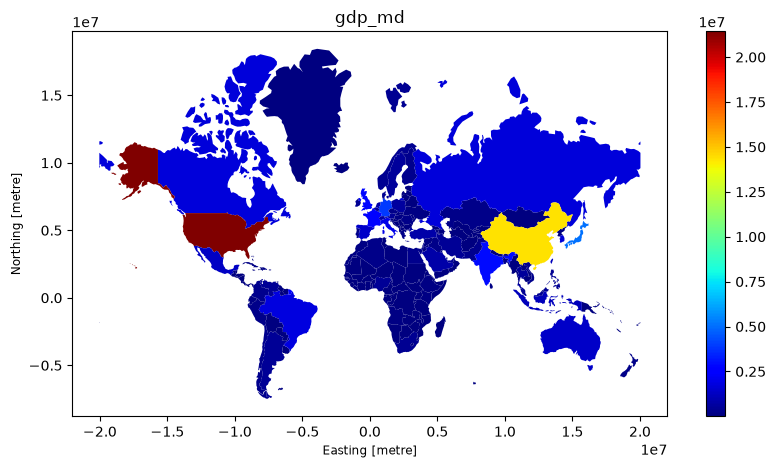

In [35]:
ax = world.to_crs("EPSG:3857").plot(column="GDP_MD", cmap="jet", legend=True, figsize=(10, 5))
ax.set_title("gdp_md");

In [ ]:
# Your improved map here